# Cat, Dog, or Neither — Capstone notebook

This notebook drives the `catdog` package. All real logic lives in the package, so the CLI, the web app and this notebook
behave identically.

| Section | What it does | Runs on assessment day? |
|---|---|---|
| 0. Setup | download the project, install, connect Google Drive, copy your photos | ✅ |
| 1. Look at the data | grids, class lists, exclusions | only if `TRAIN` |
| 2. Approach B (baseline + evidence) | two-class model + threshold study | only if `TRAIN` |
| 3. Approach A (shipped model) | three-class model + tuned threshold, then **save to Drive** | only if `TRAIN` |
| 4. Own held-out set | confusion matrix on *your* photos | ✅ (fast) |
| 5. Reload proof | loads `model.keras` in a fresh process | ✅ |
| **6. ASSESSMENT CELL** | **change one line — the folder — and run** | ✅ |

**Runtime → Change runtime type → T4 GPU** before training. With `TRAIN = False`, *Restart and run all* never retrains.

**Your photos live in Google Drive**, in `MyDrive/catdog/` (the first run creates the folders for you):

```
MyDrive/catdog/own/neither/      30–40+ photos of things that are NOT cats or dogs (your surroundings)
MyDrive/catdog/own/cat/          optional: your own cat photos
MyDrive/catdog/own/dog/          optional: your own dog photos
MyDrive/catdog/holdout/cat/      photos the model NEVER trains on — your own test set (20+ in total)
MyDrive/catdog/holdout/dog/
MyDrive/catdog/holdout/neither/
MyDrive/catdog/artifacts/        the trained model is saved here after training
```

In [29]:
# ---- 0. Setup -------------------------------------------------------------
TRAIN = False          # True only when you want to (re)train. Assessment day: False.
REPO_URL = "https://github.com/okoko-sunday/capstone_claude.git"   # <- the project on GitHub
PROJECT = "/content/catdog"                                        # where the project lives in Colab
DRIVE_DIR = "/content/drive/MyDrive/catdog"                        # your photos + the saved model

import os, sys, subprocess, shutil
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists(PROJECT):
    url, token = REPO_URL, ""
    try:
        # Private repo? Add a GitHub token as a Colab secret named GITHUB_TOKEN
        # (key icon in the left sidebar → Add new secret → turn on "Notebook access").
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN") or ""
    except Exception:
        pass  # no secret: fine for a public repo
    if token:
        url = REPO_URL.replace("https://", f"https://x-access-token:{token}@")
    r = subprocess.run(["git", "clone", "--depth", "1", url, PROJECT], capture_output=True, text=True)
    if r.returncode != 0:
        msg = (r.stderr or "").replace(token, "***") if token else r.stderr
        raise RuntimeError("Could not download the project from GitHub.\n"
                           "Either make the repository public, or add a GITHUB_TOKEN secret (see the comment above).\n\n" + msg)
if not IN_COLAB:
    PROJECT = os.path.abspath("..")  # running locally from notebooks/
os.chdir(PROJECT)
sys.path.insert(0, PROJECT)
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow-datasets", "importlib_resources", "pillow-heif"], check=True)

import tensorflow as tf
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")
print("Project:", PROJECT)

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project: /content/catdog


In [30]:
# ---- Google Drive: your photos in, the saved model back ---------------------------
# Datasets (≈1.1 GB) download to Colab's own fast disk, not Drive: training reads them
# constantly and Drive would make it many times slower. They re-download after a reset.
from pathlib import Path

def copy_tree(src, dst, only=None):
    """Copy every file under src into dst (keeping sub-folders). Returns the count."""
    src, dst, n = Path(src), Path(dst), 0
    if not src.is_dir():
        return 0
    for f in src.rglob("*"):
        rel = f.relative_to(src)
        if f.is_file() and not f.name.startswith(".") and (only is None or rel.parts[0] in only):
            (dst / rel).parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(f, dst / rel)
            n += 1
    return n

def count_photos(root):
    exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".heic", ".heif", ".gif", ".tif", ".tiff"}
    return {lab: sum(1 for f in Path(root, lab).glob("*") if f.suffix.lower() in exts) for lab in ("cat", "dog", "neither")}

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    for sub in ("own/cat", "own/dog", "own/neither", "holdout/cat", "holdout/dog", "holdout/neither", "artifacts"):
        Path(DRIVE_DIR, sub).mkdir(parents=True, exist_ok=True)   # first run: creates the folders for you
    for part in ("own", "holdout"):
        copy_tree(f"{DRIVE_DIR}/{part}", f"data/{part}")
    # Assessment day / any run without training: use the model saved by an earlier training run.
    if not TRAIN and not Path("artifacts/model.keras").exists() and Path(DRIVE_DIR, "artifacts/model.keras").exists():
        copy_tree(f"{DRIVE_DIR}/artifacts", "artifacts")
        print("Loaded the trained model from Drive.")

own, hold = count_photos("data/own"), count_photos("data/holdout")
print("Your training photos (data/own):  ", own)
print("Your held-out photos (data/holdout):", hold, "→ total", sum(hold.values()))
if own["neither"] < 30:
    print("⚠️  Fewer than 30 'neither' photos of your surroundings. The brief says these matter most — add more to Drive.")
if sum(hold.values()) < 20:
    print("⚠️  Fewer than 20 held-out photos. The brief asks for at least twenty from outside the training data.")
print("Model file present:", Path("artifacts/model.keras").exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your training photos (data/own):   {'cat': 0, 'dog': 0, 'neither': 60}
Your held-out photos (data/holdout): {'cat': 12, 'dog': 12, 'neither': 15} → total 39
Model file present: True


## 1. Look at the data
*Do not skip looking at your own data.* We read every Caltech-101 class name and decide what to exclude; the decisions
live in `catdog/data/exclusions.py` with a reason for each.

In [31]:
from catdog.data.exclusions import CALTECH101_EXCLUDE, CALTECH101_KEEP_NOTES, IMAGENETTE_EXCLUDE
if TRAIN:
    import tensorflow_datasets as tfds
    _, info = tfds.load("caltech101", split="train", with_info=True)
    names = info.features["label"].names
    print(f"Caltech-101 has {len(names)} classes:\n", ", ".join(names))
print("\nEXCLUDED from 'neither':")
for k, why in {**CALTECH101_EXCLUDE, **IMAGENETTE_EXCLUDE}.items():
    print(f"  {k:<20} {why}")
print("\nKept on purpose:")
for k, why in CALTECH101_KEEP_NOTES.items():
    print(f"  {k:<20} {why}")


EXCLUDED from 'neither':
  dalmatian            A dog breed. Labelling it 'neither' teaches the model dogs are not dogs.
  snoopy               Cartoon dog. Ambiguous ground truth; the brief's test photos are real photographs.
  garfield             Cartoon cat. Same reasoning as snoopy.
  wild_cat             Many images are tabby-like small wild cats that are visually indistinguishable from domestic cats.
  background_google    Random Google results used as clutter; unlabelled, and a spot check finds animals including pets.
  n02102040            English springer spaniel — a dog breed.

Kept on purpose:
  leopards             Big wild cat, not a house cat. Kept as 'neither': the question we answer is 'is there a pet cat?'.
  cougar_body          Large wild feline. Kept as 'neither' for the same reason as leopards.
  cougar_face          Close-up wild feline faces. Kept, but a known source of cat/neither confusion — watch this in the matrix.
  faces                People. Kept: peopl

In [32]:
import matplotlib.pyplot as plt
from catdog.config import LABELS
from catdog.data.sources import load_source

def show_grid(source, n=12, title=None):
    ds = load_source(source, seed=1, limit=n)
    fig, axes = plt.subplots(2, n // 2, figsize=(2 * n // 2, 4.4))
    for ax, (img, y) in zip(axes.flat, ds):
        ax.imshow(img.numpy()); ax.set_title(LABELS[int(y)], fontsize=9); ax.axis("off")
    fig.suptitle(title or source); plt.tight_layout(); plt.show()

if TRAIN:
    show_grid("oxford_iiit_pet", title="Oxford-IIIT Pet (species label)")
    show_grid("caltech101", title="Caltech-101 negatives — notice the plain backgrounds")
    show_grid("imagenette", title="Imagenette negatives — real scenes, clutter")

### Start small
Fifty images per source, one epoch. A bug found here costs a minute, not an evening.

In [33]:
from catdog.config import TrainConfig
from catdog.modeling.train import train
if TRAIN:
    smoke = train(TrainConfig(limit=50, head_epochs=1, finetune_epochs=0), out_dir="artifacts/smoke")

## 2. Approach B — two classes + a threshold (the evidence)
Train cats-vs-dogs only, then ask: does "top probability below *t* ⇒ neither" actually separate pets from everything else?
The study reports, for every threshold, how many pets survive and how many negatives are caught.

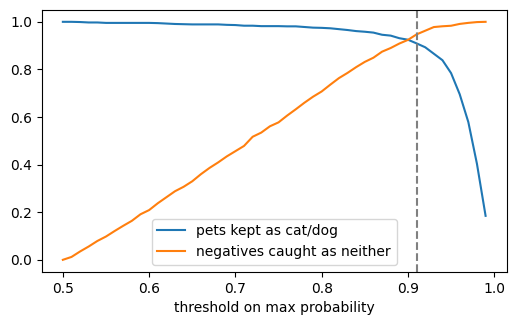

Cat-vs-dog accuracy: 99.5% | AUROC pets-vs-negatives: 0.971
Best threshold 0.91: keeps 90.9% of pets, catches 94.7% of negatives
7.6% of negatives were called cat/dog with >90% confidence


In [34]:
import json, numpy as np
if TRAIN:
    b = train(TrainConfig(finetune_epochs=0), two_class=True)
b_path = "artifacts/reports/approach_b.json"
if os.path.exists(b_path):
    b = json.load(open(b_path)); s = b["threshold_study"]
    sweep = s["sweep"]
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.plot([r["threshold"] for r in sweep], [r["pet_recall"] for r in sweep], label="pets kept as cat/dog")
    ax.plot([r["threshold"] for r in sweep], [r["neither_recall"] for r in sweep], label="negatives caught as neither")
    ax.axvline(s["best"]["threshold"], ls="--", c="gray"); ax.set_xlabel("threshold on max probability"); ax.legend(); plt.show()
    print(f"Cat-vs-dog accuracy: {b['pet_accuracy']:.1%} | AUROC pets-vs-negatives: {s['auroc']:.3f}")
    print(f"Best threshold {s['best']['threshold']:.2f}: keeps {s['best']['pet_recall']:.1%} of pets, catches {s['best']['neither_recall']:.1%} of negatives")
    print(f"{s['negatives_confident_over_90']:.1%} of negatives were called cat/dog with >90% confidence")

**Conclusion — Approach B vs A.**
The cat-vs-dog model was 99.5% accurate, but at its best threshold (0.91) it kept only 90.9% of pets (about 100 real cats and dogs pushed into "neither") and still let 5.3% of non-pets through. Worse, 7.6% of non-pet photos (69 of 909) were called cat or dog with more than 90% confidence — confident and wrong, so no threshold can catch them. So we moved to Approach A (three classes + a 0.34 safety-net threshold): 2,006 / 2,013 correct on validation, and 1 of 909 non-pets wrong.

## 3. Approach A — three classes (the shipped model)
`neither` is a trained class built from Caltech-101 (minus pet-like classes), Imagenette (minus its dog class) and
**your own photos** in `data/own/{cat,dog,neither}/`. A safety-net threshold is then tuned on validation data.

Train counts per source: {
 "oxford_iiit_pet": {
  "cat": 1993,
  "dog": 4252
 },
 "caltech101": {
  "neither": 2550
 },
 "imagenette": {
  "neither": 2550
 },
 "own": {
  "neither": 51
 }
}
                        PREDICTED         
                     cat      dog  neither
            cat      375        2        1   = 378
TRUE        dog        3      723        0   = 726
        neither        1        0      908   = 909

Accuracy: 2006/2013 = 99.7%
class       precision   recall       f1  support
cat             98.9%    99.2%    99.1%      378
dog             99.7%    99.6%    99.7%      726
neither         99.9%    99.9%    99.9%      909


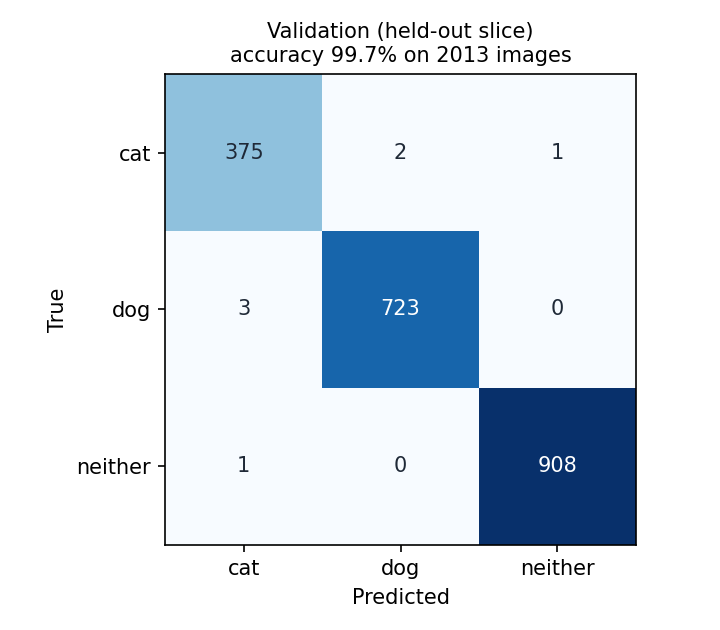

In [35]:
from catdog.evaluation.metrics import EvaluationReport, ClassReport, format_report
from IPython.display import Image as IPImage, display
if TRAIN:
    meta = train(TrainConfig())
meta = json.load(open("artifacts/model_meta.json"))
print("Train counts per source:", json.dumps(meta["train_counts"], indent=1))
v = meta["validation"]["tuned"]
print(format_report(EvaluationReport(**{**v, "per_class": [ClassReport(**c) for c in v["per_class"]]})))
if os.path.exists("artifacts/reports/validation_confusion.png"):
    display(IPImage("artifacts/reports/validation_confusion.png", width=420))

### 3b. Save the model — do not skip
Colab deletes everything when the session ends. This copies the trained model to `MyDrive/catdog/artifacts/` and
downloads a zip, so you can put `model.keras`, `model_meta.json` and `reports/` into the project's `artifacts/` folder
on your laptop (for the web app) and commit them (the brief wants the saved model in the repository).

In [36]:
KEEP = {"model.keras", "model_meta.json", "reports"}
if TRAIN and IN_COLAB and Path("artifacts/model.keras").exists():
    n = copy_tree("artifacts", f"{DRIVE_DIR}/artifacts", only=KEEP)
    print(f"Saved {n} files to {DRIVE_DIR}/artifacts")
    zip_path = shutil.make_archive("/content/catdog_artifacts", "zip", f"{DRIVE_DIR}/artifacts")  # only the files you need
    from google.colab import files
    files.download(zip_path)   # catdog_artifacts.zip → unzip into the project's artifacts/ folder
elif not TRAIN:
    print("TRAIN is False — nothing new to save.")

TRAIN is False — nothing new to save.


## 4. Your own held-out set — the number that matters
Put photos the model has **never** trained on in `data/holdout/{cat,dog,neither}/` (at least 20, from your phone, friends,
anywhere but the training data). This is the matrix you bring on the day.

W0000 00:00:1793029021.306065   69774 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
W0000 00:00:1793029026.899858   69774 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: goo.gle/debugproto  
batch: 16
in_depths: 32
out_depths: 128
in: 57
in: 57
data_format: 1
filter: 3
filter: 3
filter: 32
dilation: 1
dilation: 1
stride: 2
stride: 2
padding: 0
padding: 0
dtype: DT_FLOAT
group_count: 1
device_identifier: "sm_7.5 with 15.6GB RAM, 40 cores, 1590000KHz clock, 5001000KHz mem clock, 4194304B L2$"
version: 3

W0000 00:00:1793029028.946748   69774 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: goo.gle/debugproto  
batch: 7
in_depths: 32
out_depths: 128
in: 57
in: 57
data_format: 1
filter: 3
filter: 3
filter: 32
dilation: 1
dilation: 1

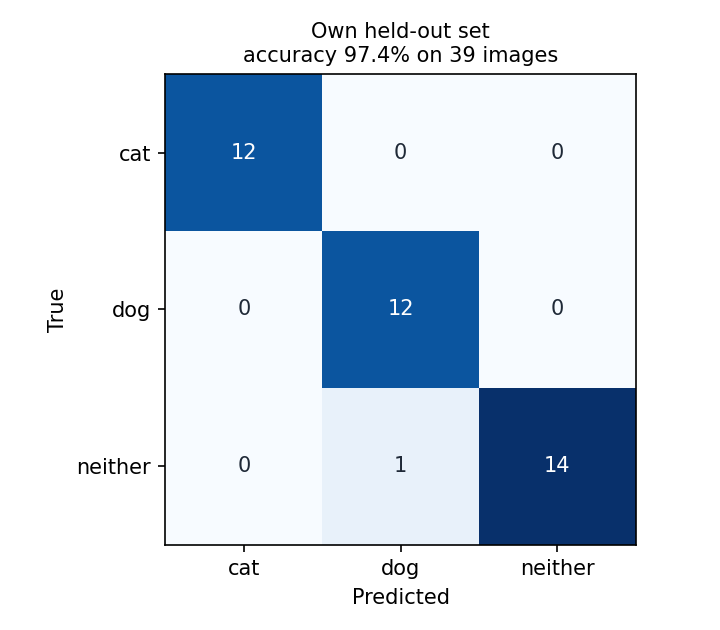

In [37]:
!python -m catdog evaluate data/holdout
if os.path.exists("artifacts/reports/holdout_confusion.png"):
    display(IPImage("artifacts/reports/holdout_confusion.png", width=420))

## 5. Reload proof
A separate Python process loads `model.keras` from disk — nothing from this notebook's memory is used.

In [38]:
!python -m catdog info | head -n 20

W0000 00:00:1793029040.546293   69946 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
{
  "trained_at": "2026-10-26T09:03:28+00:00",
  "train_seconds": 410.6,
  "config": {
    "image_size": 224,
    "batch_size": 32,
    "backbone": "efficientnetv2b0",
    "head_epochs": 6,
    "head_lr": 0.001,
    "finetune_epochs": 4,
    "finetune_lr": 1e-05,
    "finetune_layers": 40,
    "dropout": 0.3,
    "label_smoothing": 0.05,
    "val_fraction": 0.15,
    "seed": 42,
    "max_per_class": 4000,
    "limit": null,
    "sources": [
      "oxford_iiit_pet",
Exception ignored on flushing sys.stdout:
BrokenPipeError: [Errno 32] Broken pipe


---
## 6. 🎯 ASSESSMENT CELL
Change **one line** — the folder — and run. Handles any size, shape, PNG/JPEG/HEIC, portrait/landscape; unreadable files
become an `error` row instead of crashing.

In [39]:
# Optional upload helper: set UPLOAD = True, run this cell, click "Choose files" and pick all the photos.
# (Or drag them into a "test_images" folder in the Files panel on the left.)
UPLOAD = False
if UPLOAD and IN_COLAB:
    from google.colab import files
    Path("/content/test_images").mkdir(exist_ok=True)
    for name, data in files.upload().items():
        Path("/content/test_images", name).write_bytes(data)
    print(len(list(Path("/content/test_images").iterdir())), "photos in /content/test_images")

In [40]:
FOLDER = "/content/test_images"   # <- the only line you change

import sys; sys.path.insert(0, PROJECT)
from pathlib import Path
from catdog.inference import predict_folder_table
if Path(FOLDER).is_dir():
    predictions = predict_folder_table(FOLDER)
else:
    print(f"No folder at {FOLDER} yet.")
    print("Put the test photos there (Files panel → New folder → test_images, or use the upload helper above),")
    print('then run this cell again. Rehearse with: FOLDER = "/content/catdog/data/holdout/neither"')

No folder at /content/test_images yet.
Put the test photos there (Files panel → New folder → test_images, or use the upload helper above),
then run this cell again. Rehearse with: FOLDER = "/content/catdog/data/holdout/neither"


## 7. Break it on purpose
List the photos that defeat it, and why we think they do.

| Photo | True | Predicted | Confidence |
|---|---|---|---|
| neither_008.jpg (a goat) | neither | dog | 56.3% |

**Why the goat failed**
- A goat is four-legged, furry and dog-sized, and is usually photographed outdoors, like most dog photos.
- There are only a few goats among the 5,151 "neither" training photos.
- The model was unsure: dog 56%, neither 38%, cat 6%.
- 56% is above the 0.34 safety-net threshold, so it was not switched to "neither".

**Fix:** add more goats, sheep and other farm animals to the "neither" training set.